## Carga y comprension del dataset

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# configuracion visualizacion
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', "{:.6f}".format)

# raiz del proyecto
cwd = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        ruta
        for ruta in (cwd, *cwd.parents)
        if (ruta / "data" / "interim").is_dir()
        and (ruta / "notebooks").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se pudo localizar la raíz del proyecto."
    )

# Directorio de datos
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"

# Cargar panel
panel = pd.read_parquet(
    INTERIM_DIR / "panel_bancario_2026_09.parquet"
)

# Asegurar formato de fechas
panel["fecha"] = pd.to_datetime(panel["fecha"])

# Ordenar observaciones
panel = (
    panel
    .sort_values(["banco", "fecha"])
    .reset_index(drop=True)
)

print("Dimensiones:", panel.shape)
print("Instituciones:", panel["banco"].nunique())

print("\nPeríodo histórico:")
print("Inicio:", panel["fecha"].min())
print("Fin:", panel["fecha"].max())

print("\nDuplicados banco-mes:")
print(panel.duplicated(["banco", "fecha"]).sum())

display(panel.head())

Dimensiones: (5972, 11)
Instituciones: 23

Período histórico:
Inicio: 2003-01-01 00:00:00
Fin: 2026-09-01 00:00:00

Duplicados banco-mes:
0


,fecha,banco,solvencia,liquidez,roa,roe,cartera_depositos,cartera_bruta,cartera_improductiva,morosidad_total,cobertura
0,2011-07-01,BANCO ATLANTIDA S.A.,NaN,0.000000,0.019541,0.091531,0.000000,31872.724310,828.743660,0.026002,0.776931
1,2011-08-01,BANCO ATLANTIDA S.A.,0.251770,0.000000,0.018258,0.085764,0.000000,33162.498160,728.989740,0.021982,1.002009
2,2011-09-01,BANCO ATLANTIDA S.A.,0.288140,0.000000,0.017008,0.081672,0.000000,34827.652490,822.659430,0.023621,1.003828
3,2011-10-01,BANCO ATLANTIDA S.A.,0.269500,0.000000,0.016025,0.073058,0.000000,36890.476810,909.871570,0.024664,1.026205
4,2011-11-01,BANCO ATLANTIDA S.A.,0.260570,0.000000,0.015737,0.070117,0.000000,38955.554030,1020.616170,0.026200,1.007305


### Cuantos bancos privados disponen de informacion en cada mes del periodo historico

Trabajaremos con un panel desbalanceado, tenemos bancos con menor informacion que otros

In [2]:
# Cantidad de instituciones con registros por mes
cobertura_mensual = (
    panel
    .groupby("fecha")
    .agg(
        bancos_disponibles=("banco", "nunique"),
        observaciones=("banco", "size"),
        morosidad_disponible=("morosidad_total", "count")
    )
    .reset_index()
)

print("Resumen de cobertura mensual:")

display(cobertura_mensual.head(10))
display(cobertura_mensual.tail(10))

print("\nEstadísticas de cobertura:")

display(
    cobertura_mensual[
        ["bancos_disponibles", "morosidad_disponible"]
    ].describe()
)

Resumen de cobertura mensual:


,fecha,bancos_disponibles,observaciones,morosidad_disponible
0,2003-01-01,18,18,18
1,2003-02-01,18,18,18
2,2003-03-01,18,18,18
3,2003-04-01,18,18,18
4,2003-05-01,18,18,18
5,2003-06-01,18,18,18
6,2003-07-01,18,18,18
7,2003-08-01,18,18,18
8,2003-09-01,18,18,18
9,2003-10-01,18,18,18


,fecha,bancos_disponibles,observaciones,morosidad_disponible
275,2025-12-01,23,23,23
276,2026-01-01,23,23,23
277,2026-02-01,23,23,23
278,2026-03-01,23,23,23
279,2026-04-01,23,23,23
280,2026-05-01,23,23,23
281,2026-06-01,23,23,23
282,2026-07-01,23,23,23
283,2026-08-01,23,23,23
284,2026-09-01,23,23,23



Estadísticas de cobertura:


,bancos_disponibles,morosidad_disponible
count,285.000000,285.000000
mean,20.954386,20.933333
std,1.825491,1.853559
min,18.000000,18.000000
25%,19.000000,19.000000
50%,21.000000,21.000000
75%,23.000000,23.000000
max,23.000000,23.000000


## evolucion de la cobertura mensual

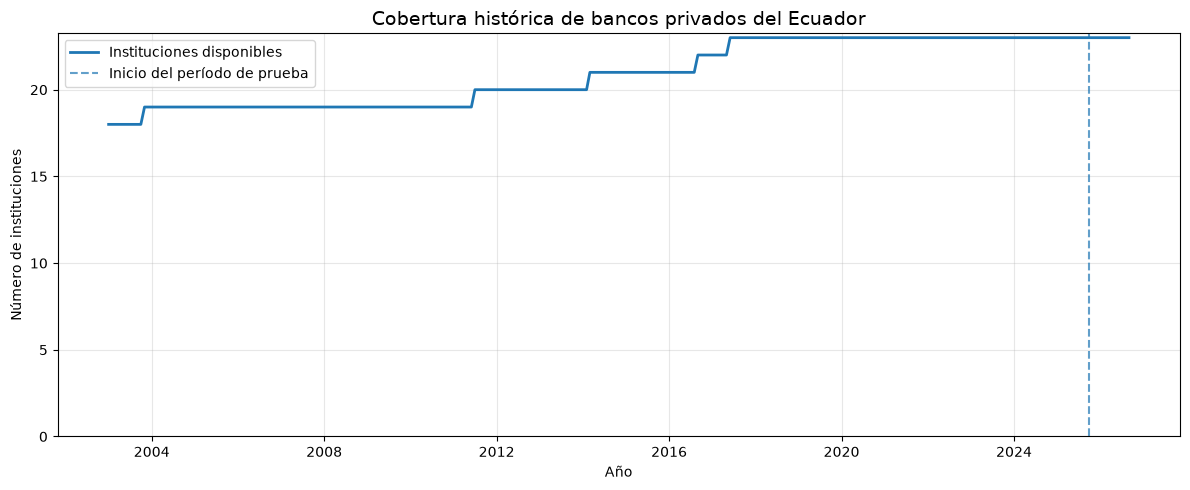

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    cobertura_mensual["fecha"],
    cobertura_mensual["bancos_disponibles"],
    linewidth=2,
    label="Instituciones disponibles"
)

ax.axvline(
    pd.Timestamp("2025-10-01"),
    linestyle="--",
    alpha=0.7,
    label="Inicio del período de prueba"
)

ax.set_title(
    "Cobertura histórica de bancos privados del Ecuador",
    fontsize=14
)

ax.set_xlabel("Año")
ax.set_ylabel("Número de instituciones")

ax.set_ylim(bottom=0)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

desde el 2018 tenemos la informacion de todos los bancos. En 2003 tenemos informacion desde los 18 bancos

## estudio de la variable objetivo Morosidad bancaria

morosidad = cartera improductiva / cartera bruta

Como se distribuye historicamente la morosidad de los bancos privados ecuatorianos y que tan frecuentes son los valores extremos?

Separar el periodo de desarrollo con el de prueba
Desarrollo hasta el 2025-08-01, a partir de esa fecha, prueba

In [4]:
# Separar el período de desarrollo
fecha_corte = pd.Timestamp("2025-09-01")

desarrollo = panel.loc[
    panel["fecha"] <= fecha_corte
].copy()

# Convertir morosidad a puntos porcentuales
desarrollo["morosidad_pp"] = (
    desarrollo["morosidad_total"] * 100
)

# Información general
print("Observaciones de desarrollo:", len(desarrollo))

print(
    "Instituciones:",
    desarrollo["banco"].nunique()
)

print(
    "Morosidad disponible:",
    desarrollo["morosidad_pp"].notna().sum()
)

# Estadísticas descriptivas
estadisticas = desarrollo["morosidad_pp"].describe(
    percentiles=[
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.99
    ]
)

display(estadisticas)

Observaciones de desarrollo: 5696
Instituciones: 23
Morosidad disponible: 5690


count   5690.000000
mean       4.837328
std        6.071565
min        0.000000
1%         0.000001
5%         0.189938
25%        1.937143
50%        3.620592
75%        5.994109
95%       11.891839
99%       27.430599
max       87.043435
Name: morosidad_pp, dtype: float64

Distribucion de la variable

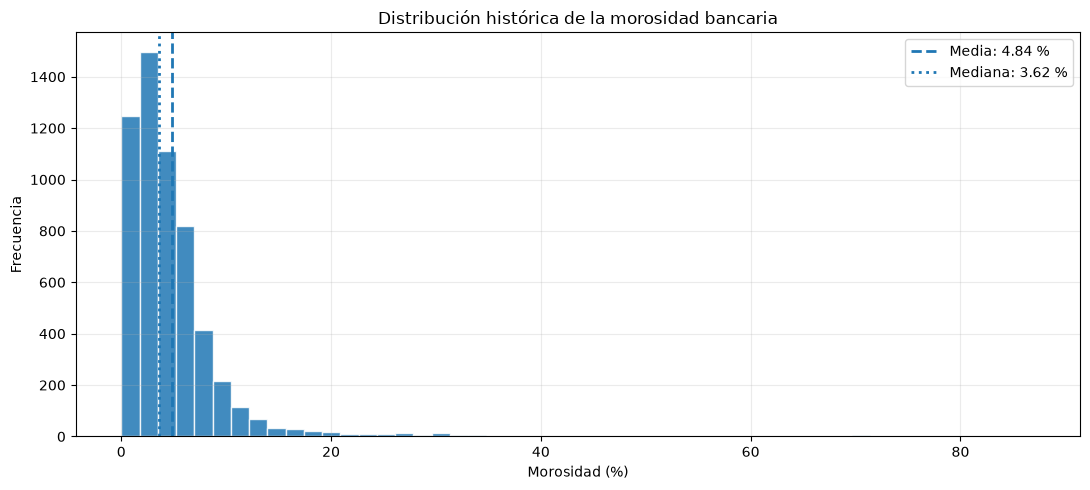

In [5]:
# Seleccionar observaciones válidas
morosidad = desarrollo["morosidad_pp"].dropna()

# Crear gráfico
fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    morosidad,
    bins=50,
    edgecolor="white",
    alpha=0.85
)

# Media y mediana
media = morosidad.mean()
mediana = morosidad.median()

ax.axvline(
    media,
    linestyle="--",
    linewidth=2,
    label=f"Media: {media:.2f} %"
)

ax.axvline(
    mediana,
    linestyle=":",
    linewidth=2,
    label=f"Mediana: {mediana:.2f} %"
)

ax.set_title(
    "Distribución histórica de la morosidad bancaria"
)

ax.set_xlabel("Morosidad (%)")
ax.set_ylabel("Frecuencia")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

La distribución histórica de la morosidad bancaria presenta una marcada asimetría positiva, con una media de 4,84 % y una mediana de 3,62 %. La mayoría de las observaciones se concentra en niveles relativamente moderados, aunque existen valores extremos que alcanzan el 87,04 %. Estos resultados sugieren una considerable heterogeneidad en el comportamiento de la morosidad, por lo que resulta necesario analizar las diferencias entre instituciones y examinar los valores atípicos antes del modelado.

### Que diferencias existen en los niveles y la variabilidad de la morosidad entre las instituciones financieras ecuatorianas?

In [6]:
# Estadísticas descriptivas de morosidad por institución

resumen_bancos = (
    desarrollo
    .groupby("banco")["morosidad_pp"]
    .agg(
        observaciones="count",
        media="mean",
        mediana="median",
        desviacion="std",
        minimo="min",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        p95=lambda x: x.quantile(0.95),
        maximo="max"
    )
)

# Calcular el rango intercuartílico
resumen_bancos["iqr"] = (
    resumen_bancos["q3"] - resumen_bancos["q1"]
)

# Ordenar por mediana
resumen_bancos = resumen_bancos.sort_values(
    "mediana",
    ascending=False
)

display(resumen_bancos.round(3))

,observaciones,media,mediana,desviacion,minimo,q1,q3,p95,maximo,iqr
banco,,,,,,,,,,
BP LITORAL,273,8.791000,8.800000,3.416000,2.614000,6.076000,10.979000,14.713000,20.284000,4.903000
BP CAPITAL,273,15.099000,8.308000,19.139000,1.591000,5.261000,12.749000,70.416000,87.043000,7.488000
"BP BANCO DESARROLLO DE LOS PUEBLOS S.A., CODESARROLLO",139,7.195000,7.230000,1.242000,5.045000,6.024000,8.066000,9.292000,9.982000,2.042000
BANCO ATLANTIDA S.A.,171,9.171000,7.048000,4.755000,2.198000,6.138000,12.501000,18.416000,22.198000,6.363000
BANCO COMERCIAL DE MANABI,273,6.783000,6.523000,2.693000,1.693000,4.985000,8.461000,10.983000,15.792000,3.476000
BP SOLIDARIO,273,6.365000,6.217000,1.671000,0.856000,5.396000,7.571000,9.051000,11.656000,2.175000
BP AUSTRO,273,6.887000,5.635000,4.438000,2.380000,4.402000,7.071000,17.173000,30.448000,2.669000
BP AMAZONAS,273,4.842000,4.754000,1.516000,0.746000,3.660000,5.825000,7.312000,9.942000,2.165000
BP VISIONFUND ECUADOR S.A.,109,4.589000,4.695000,1.356000,2.433000,3.415000,5.761000,6.719000,7.281000,2.345000


/tmp/ipykernel_5942/3995149131.py:21: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


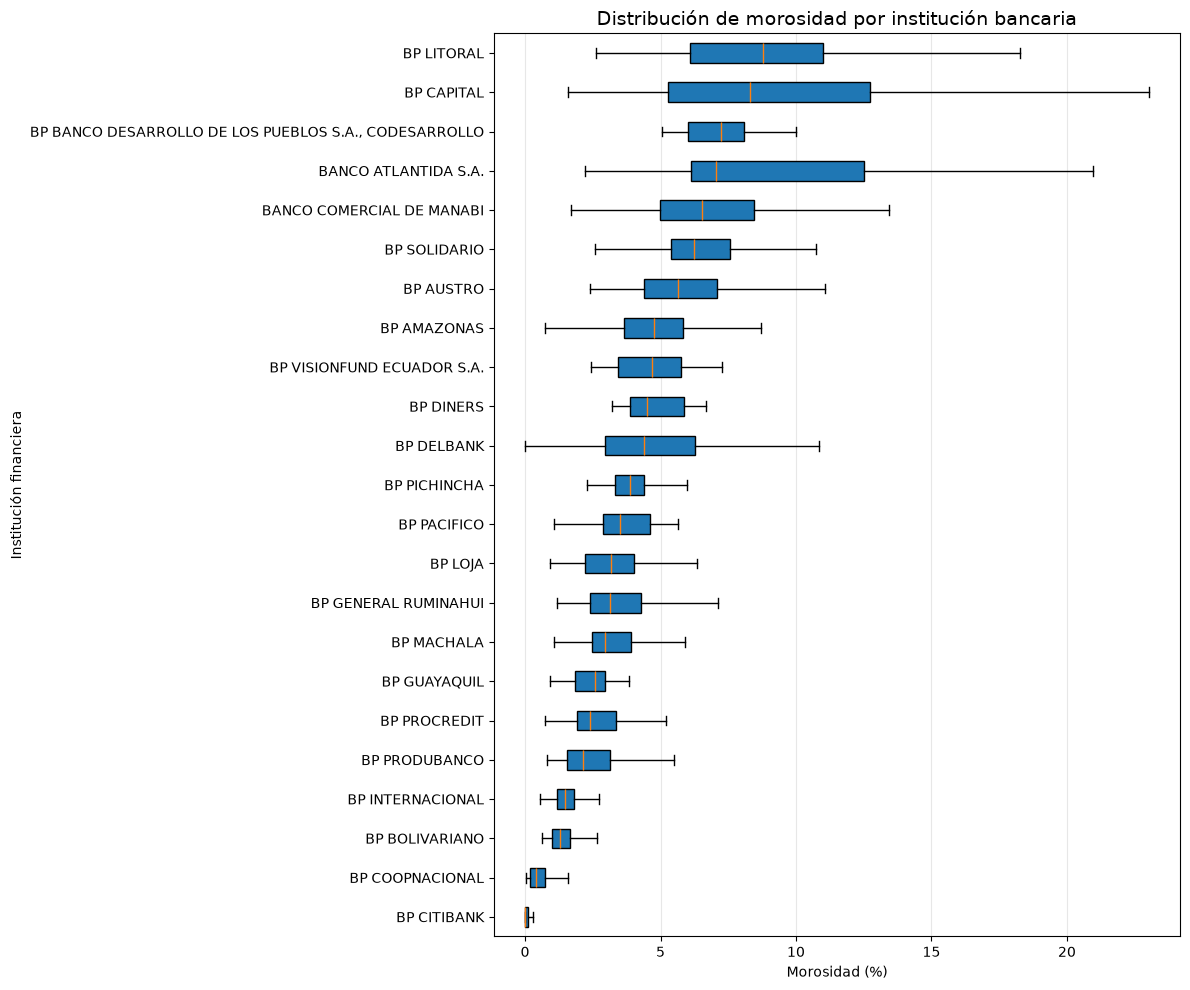

In [7]:
# Ordenar instituciones según su mediana
bancos_ordenados = (
    resumen_bancos
    .sort_values("mediana")
    .index
    .tolist()
)

# Preparar los datos para los boxplots
datos_boxplot = [
    desarrollo.loc[
        desarrollo["banco"] == banco,
        "morosidad_pp"
    ].dropna().to_numpy()
    for banco in bancos_ordenados
]

# Crear figura
fig, ax = plt.subplots(figsize=(12, 10))

ax.boxplot(
    datos_boxplot,
    vert=False,
    showfliers=False,
    patch_artist=True
)

ax.set_yticks(
    range(1, len(bancos_ordenados) + 1),
    labels=bancos_ordenados
)

ax.set_title(
    "Distribución de morosidad por institución bancaria",
    fontsize=14
)

ax.set_xlabel("Morosidad (%)")
ax.set_ylabel("Institución financiera")

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# Identificar las 15 observaciones con mayor morosidad

valores_extremos = (
    desarrollo
    .nlargest(
        15,
        "morosidad_pp"
    )
    [
        [
            "fecha",
            "banco",
            "morosidad_pp",
            "cartera_bruta",
            "cartera_improductiva"
        ]
    ]
)

display(valores_extremos)

,fecha,banco,morosidad_pp,cartera_bruta,cartera_improductiva
1671,2019-06-01,BP CAPITAL,87.043435,8643.697660,7523.771390
1670,2019-05-01,BP CAPITAL,86.219913,8872.954630,7650.253740
1669,2019-04-01,BP CAPITAL,85.068776,9099.717950,7741.018670
1668,2019-03-01,BP CAPITAL,84.987768,9431.920950,8015.979110
1666,2019-01-01,BP CAPITAL,84.347478,10873.695800,9171.688140
1667,2019-02-01,BP CAPITAL,83.352256,9832.961740,8195.995470
1672,2019-07-01,BP CAPITAL,82.413760,8946.352890,7373.025800
1665,2018-12-01,BP CAPITAL,80.737292,10129.267120,8178.096010
1673,2019-08-01,BP CAPITAL,79.921933,9104.267810,7276.306810
1664,2018-11-01,BP CAPITAL,75.886162,9133.254220,6930.876080


## Evolucion temporal de la morosidad

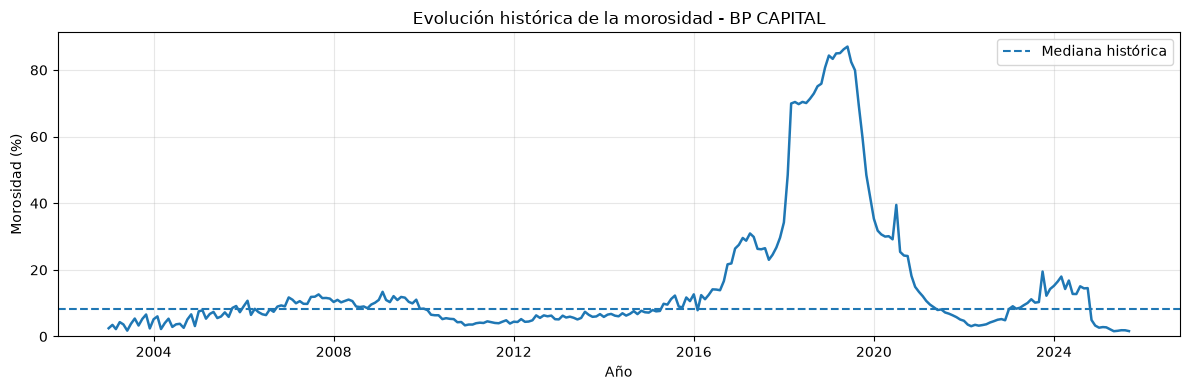

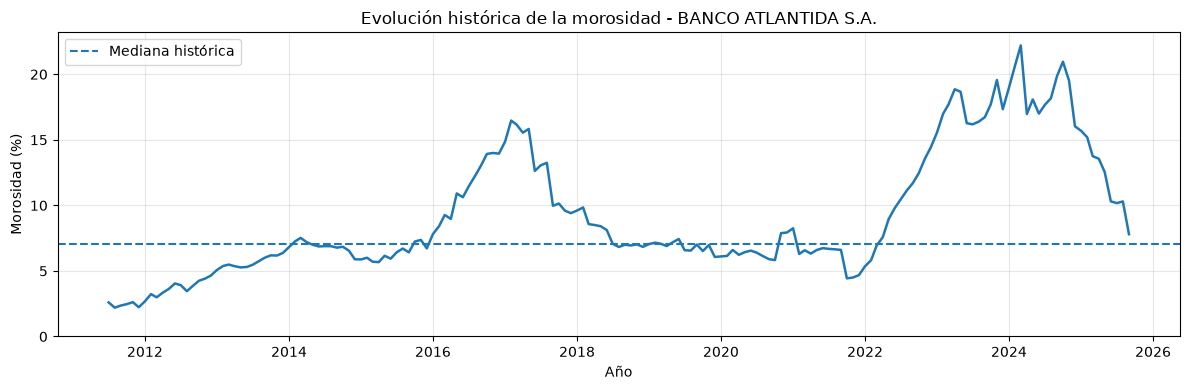

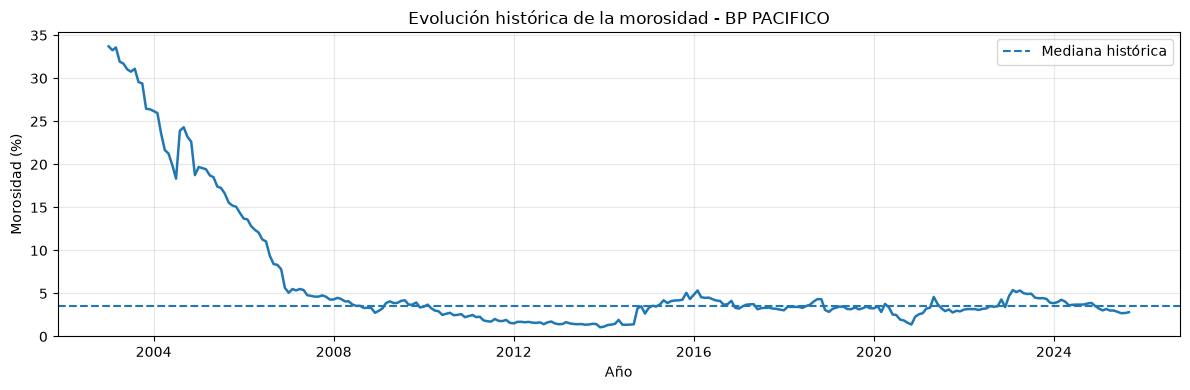

In [9]:
# Instituciones seleccionadas
bancos_analisis = [
    "BP CAPITAL",
    "BANCO ATLANTIDA S.A.",
    "BP PACIFICO"
]

for banco in bancos_analisis:

    df_banco = (
        desarrollo.loc[
            desarrollo["banco"] == banco
        ]
        .sort_values("fecha")
    )

    fig, ax = plt.subplots(figsize=(12, 4))

    ax.plot(
        df_banco["fecha"],
        df_banco["morosidad_pp"],
        linewidth=1.8
    )

    ax.axhline(
        df_banco["morosidad_pp"].median(),
        linestyle="--",
        label="Mediana histórica"
    )

    ax.set_title(
        f"Evolución histórica de la morosidad - {banco}"
    )

    ax.set_xlabel("Año")
    ax.set_ylabel("Morosidad (%)")

    ax.set_ylim(bottom=0)

    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

## Investigar la cartera bruta e improductiva de banco capital

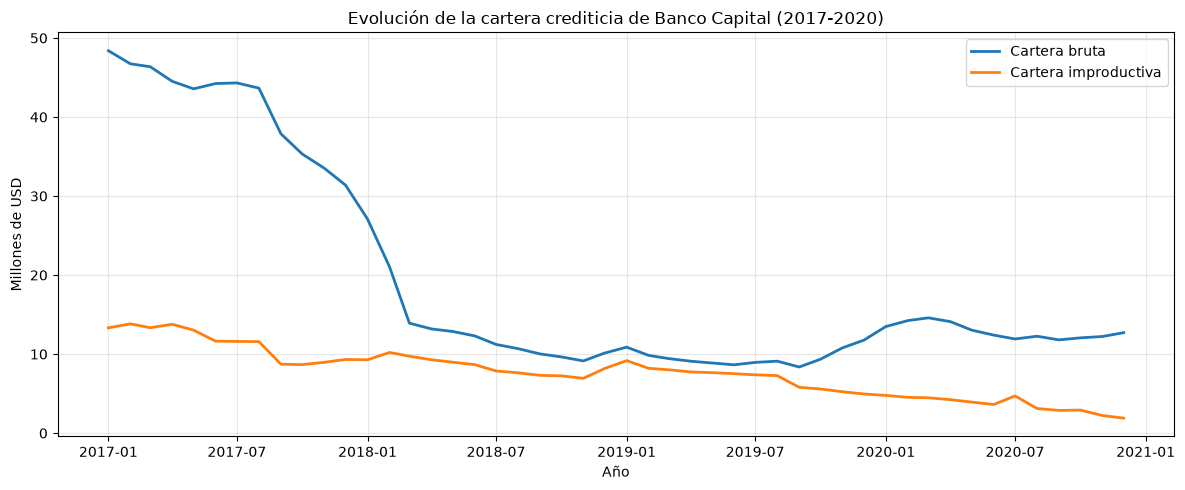

In [10]:
# Seleccionar Banco Capital
capital = desarrollo.loc[
    (desarrollo["banco"] == "BP CAPITAL")
    & desarrollo["fecha"].between(
        "2017-01-01",
        "2020-12-01"
    )
].copy()

# Convertir miles de USD a millones de USD
capital["cartera_bruta_millones"] = (
    capital["cartera_bruta"] / 1000
)

capital["cartera_improductiva_millones"] = (
    capital["cartera_improductiva"] / 1000
)

# Visualizar evolución de ambas carteras
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    capital["fecha"],
    capital["cartera_bruta_millones"],
    label="Cartera bruta",
    linewidth=2
)

ax.plot(
    capital["fecha"],
    capital["cartera_improductiva_millones"],
    label="Cartera improductiva",
    linewidth=2
)

ax.set_title(
    "Evolución de la cartera crediticia de Banco Capital (2017-2020)"
)

ax.set_xlabel("Año")
ax.set_ylabel("Millones de USD")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

El análisis por institución evidencia una considerable heterogeneidad en la distribución histórica de la morosidad bancaria. Banco Capital presenta la mayor dispersión y concentra los valores más extremos, alcanzando una morosidad máxima del 87,04 % durante junio de 2019. Estos valores forman parte de un episodio prolongado entre 2018 y 2019, por lo que no corresponden a una observación aislada.
Banco Atlántida presenta niveles relativamente elevados de morosidad y una dispersión apreciable, aunque sin alcanzar los extremos de Banco Capital. Asimismo, Banco Pacífico muestra una diferencia importante entre su media y mediana, lo que sugiere la presencia de períodos de deterioro crediticio.
Estos resultados justifican realizar un análisis temporal individualizado y conservar las observaciones extremas financieramente verificadas. Para el posterior modelado será necesario evaluar el desempeño por institución y examinar si los errores predictivos aumentan durante episodios de morosidad elevada.

## Calcular series historicas

In [11]:
# Seleccionar observaciones financieramente válidas
condicion = (
    desarrollo["morosidad_total"].notna()
    & desarrollo["cartera_bruta"].gt(0)
    & desarrollo["cartera_improductiva"].ge(0)
    & (
        desarrollo["cartera_improductiva"]
        <= desarrollo["cartera_bruta"]
    )
)

datos_validos = desarrollo.loc[condicion].copy()

# Calcular ambas series históricas
morosidad_historica = (
    datos_validos
    .groupby("fecha")
    .agg(
        bancos=("banco", "nunique"),
        morosidad_media=("morosidad_pp", "mean"),
        cartera_bruta=("cartera_bruta", "sum"),
        cartera_improductiva=("cartera_improductiva", "sum")
    )
    .reset_index()
)

# Calcular morosidad ponderada por cartera
morosidad_historica["morosidad_ponderada"] = (
    morosidad_historica["cartera_improductiva"]
    / morosidad_historica["cartera_bruta"]
) * 100

# Diferencia entre los indicadores
morosidad_historica["diferencia_pp"] = (
    morosidad_historica["morosidad_media"]
    - morosidad_historica["morosidad_ponderada"]
)

print("Dimensiones:", morosidad_historica.shape)

display(morosidad_historica.head())
display(morosidad_historica.tail())

Dimensiones: (273, 7)


,fecha,bancos,morosidad_media,cartera_bruta,cartera_improductiva,morosidad_ponderada,diferencia_pp
0,2003-01-01,18,8.767045,2818816.507020,267625.935400,9.494266,-0.727221
1,2003-02-01,18,9.532202,2811216.870200,275502.253900,9.800107,-0.267905
2,2003-03-01,18,9.096095,2805758.804080,278080.411340,9.911059,-0.814964
3,2003-04-01,18,8.722940,2818202.235660,268165.076150,9.515466,-0.792526
4,2003-05-01,18,9.195974,2854950.759840,287194.348530,10.059520,-0.863546


,fecha,bancos,morosidad_media,cartera_bruta,cartera_improductiva,morosidad_ponderada,diferencia_pp
268,2025-05-01,23,4.176171,47657198.522260,1559469.108280,3.272263,0.903907
269,2025-06-01,23,3.931936,48115625.585610,1557050.768100,3.236061,0.695876
270,2025-07-01,23,3.916473,48498188.345420,1567477.970810,3.232034,0.684439
271,2025-08-01,23,3.974390,48897337.651170,1584003.635800,3.239448,0.734943
272,2025-09-01,23,3.746194,49456824.029980,1587718.345780,3.210312,0.535882


## Comaprar las series graficamente

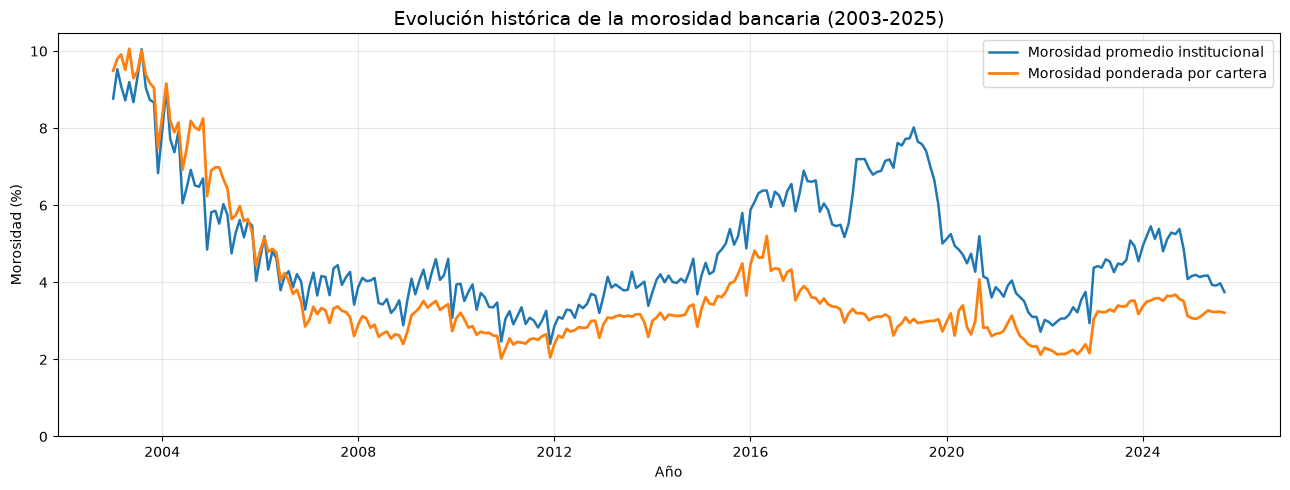

In [12]:
fig, ax = plt.subplots(figsize=(13, 5))

# Morosidad media institucional
ax.plot(
    morosidad_historica["fecha"],
    morosidad_historica["morosidad_media"],
    linewidth=1.8,
    label="Morosidad promedio institucional"
)

# Morosidad agregada ponderada
ax.plot(
    morosidad_historica["fecha"],
    morosidad_historica["morosidad_ponderada"],
    linewidth=2,
    label="Morosidad ponderada por cartera"
)

ax.set_title(
    "Evolución histórica de la morosidad bancaria (2003-2025)",
    fontsize=14
)

ax.set_xlabel("Año")
ax.set_ylabel("Morosidad (%)")

ax.set_ylim(bottom=0)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## Identificar los meses con mayores diferencias

In [13]:
# Diferencia absoluta entre ambas medidas
morosidad_historica["diferencia_abs_pp"] = (
    morosidad_historica["diferencia_pp"].abs()
)

# Meses con mayores diferencias
mayores_diferencias = (
    morosidad_historica
    .nlargest(10, "diferencia_abs_pp")
    [
        [
            "fecha",
            "bancos",
            "morosidad_media",
            "morosidad_ponderada",
            "diferencia_pp"
        ]
    ]
)

display(mayores_diferencias.round(3))

/tmp/ipykernel_5942/2132947064.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(mayores_diferencias.round(3))


,fecha,bancos,morosidad_media,morosidad_ponderada,diferencia_pp
196,2019-05-01,23,8.020000,3.050000,4.970000
195,2019-04-01,23,7.739000,2.948000,4.791000
192,2019-01-01,23,7.618000,2.848000,4.770000
197,2019-06-01,23,7.648000,2.945000,4.702000
194,2019-03-01,23,7.722000,3.093000,4.629000
198,2019-07-01,23,7.587000,2.962000,4.625000
193,2019-02-01,23,7.549000,2.937000,4.612000
199,2019-08-01,23,7.411000,2.985000,4.426000
191,2018-12-01,23,6.971000,2.620000,4.351000
190,2018-11-01,23,7.189000,3.099000,4.090000


Conclusión: los niveles elevados de morosidad de una institución pequeña pueden afectar considerablemente el promedio institucional sin producir un incremento equivalente en la morosidad agregada por cartera.

El análisis histórico evidencia diferencias entre la morosidad promedio institucional y la morosidad ponderada por cartera. Durante 2018 y 2019 se observa una divergencia considerable, alcanzando una diferencia de 4,97 puntos porcentuales en mayo de 2019. Este comportamiento coincide con el episodio de elevada morosidad registrado por Banco Capital, cuya cartera relativamente pequeña reduce su influencia sobre el indicador ponderado.
Los resultados muestran que el promedio institucional puede verse afectado por instituciones con morosidades extremas, mientras que la morosidad ponderada refleja principalmente el comportamiento del volumen de cartera crediticia. Asimismo, se identifican cambios importantes en la evolución histórica de ambos indicadores, lo que sugiere investigar la estabilidad temporal de las relaciones predictivas.
Para el posterior modelado se conservarán las observaciones históricas válidas y se evaluará el desempeño por institución, evitando depender exclusivamente de una métrica global.

## Analisis de las variaciones mensuales de morosidad

La morosidad bancaria cambia gradualmente o presenta fluctuaciones mensuales importantes?

In [14]:
# Seleccionar variables necesarias
dinamica = desarrollo[
    ["fecha", "banco", "morosidad_pp"]
].copy()

# Ordenar por institución y fecha
dinamica = dinamica.sort_values(
    ["banco", "fecha"]
).reset_index(drop=True)

# Agrupar por institución
grupo = dinamica.groupby("banco")

# Obtener la morosidad del mes anterior
dinamica["morosidad_anterior_pp"] = (
    grupo["morosidad_pp"].shift(1)
)

# Obtener la fecha de la observación anterior
dinamica["fecha_anterior"] = (
    grupo["fecha"].shift(1)
)

# Comprobar que ambas fechas correspondan a meses consecutivos
mes_actual = dinamica["fecha"].dt.to_period("M")

mes_anterior = (
    dinamica["fecha_anterior"].dt.to_period("M")
)

meses_consecutivos = (
    mes_actual == mes_anterior + 1
)

# Calcular variación mensual
dinamica["variacion_mensual_pp"] = (
    dinamica["morosidad_pp"]
    - dinamica["morosidad_anterior_pp"]
).where(meses_consecutivos)

# Calcular valor absoluto
dinamica["variacion_absoluta_pp"] = (
    dinamica["variacion_mensual_pp"].abs()
)

# Estadísticas descriptivas
print("ESTADÍSTICAS DE VARIACIONES MENSUALES")

display(
    dinamica["variacion_mensual_pp"].describe(
        percentiles=[
            0.01, 0.05, 0.25,
            0.50, 0.75, 0.95, 0.99
        ]
    )
)

print("\nVariación absoluta media:")
print(dinamica["variacion_absoluta_pp"].mean())

print("\nVariación absoluta mediana:")
print(dinamica["variacion_absoluta_pp"].median())

print("\nVariaciones mayores a 5 pp en valor absoluto:")
print(
    (dinamica["variacion_absoluta_pp"] > 5).sum()
)

ESTADÍSTICAS DE VARIACIONES MENSUALES


count   5666.000000
mean      -0.016077
std        1.123992
min      -14.094392
1%        -3.815336
5%        -1.362679
25%       -0.221399
50%        0.004223
75%        0.222004
95%        1.334276
99%        3.038214
max       21.446805
Name: variacion_mensual_pp, dtype: float64


Variación absoluta media:
0.5428798967243205

Variación absoluta mediana:
0.22172270999999988

Variaciones mayores a 5 pp en valor absoluto:
42


## visualizar las variaciones mensuales

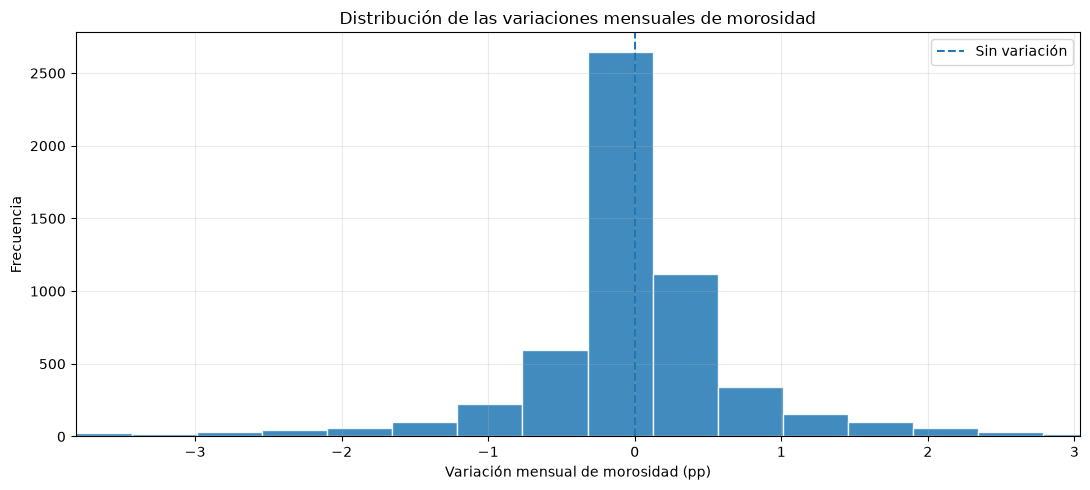

In [15]:
# Seleccionar variaciones válidas
variaciones = (
    dinamica["variacion_mensual_pp"].dropna()
)

# Percentiles para visualizar la región central
p01 = variaciones.quantile(0.01)
p99 = variaciones.quantile(0.99)

# Crear gráfico
fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    variaciones,
    bins=80,
    edgecolor="white",
    alpha=0.85
)

# Línea de referencia
ax.axvline(
    0,
    linestyle="--",
    linewidth=1.5,
    label="Sin variación"
)

ax.set_title(
    "Distribución de las variaciones mensuales de morosidad"
)

ax.set_xlabel(
    "Variación mensual de morosidad (pp)"
)

ax.set_ylabel("Frecuencia")

# Acercamiento visual al intervalo P1-P99
ax.set_xlim(p01, p99)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

## identificar cambios mensuales mas extremos

In [16]:
# Diez mayores incrementos mensuales
mayores_incrementos = (
    dinamica
    .nlargest(10, "variacion_mensual_pp")
    [
        [
            "fecha",
            "banco",
            "morosidad_anterior_pp",
            "morosidad_pp",
            "variacion_mensual_pp"
        ]
    ]
)

# Diez mayores disminuciones mensuales
mayores_disminuciones = (
    dinamica
    .nsmallest(10, "variacion_mensual_pp")
    [
        [
            "fecha",
            "banco",
            "morosidad_anterior_pp",
            "morosidad_pp",
            "variacion_mensual_pp"
        ]
    ]
)

print("MAYORES INCREMENTOS MENSUALES")
display(mayores_incrementos.round(3))

print("\nMAYORES DISMINUCIONES MENSUALES")
display(mayores_disminuciones.round(3))

MAYORES INCREMENTOS MENSUALES


/tmp/ipykernel_5942/2383498309.py:32: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(mayores_incrementos.round(3))


,fecha,banco,morosidad_anterior_pp,morosidad_pp,variacion_mensual_pp
1584,2018-03-01,BP CAPITAL,48.504000,69.950000,21.447000
1583,2018-02-01,BP CAPITAL,34.246000,48.504000,14.257000
1612,2020-07-01,BP CAPITAL,29.176000,39.501000,10.325000
1651,2023-10-01,BP CAPITAL,10.333000,19.508000,9.175000
5526,2020-09-01,BP SOLIDARIO,1.475000,10.328000,8.853000
471,2005-04-01,BP AMAZONAS,3.006000,9.942000,6.936000
3552,2015-06-01,BP LITORAL,13.745000,20.284000,6.539000
3530,2013-08-01,BP LITORAL,7.621000,13.868000,6.247000
3565,2016-07-01,BP LITORAL,11.353000,17.428000,6.076000
411,2023-01-01,BANCO COMERCIAL DE MANABI,3.286000,9.221000,5.934000



MAYORES DISMINUCIONES MENSUALES


/tmp/ipykernel_5942/2383498309.py:35: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(mayores_disminuciones.round(3))


,fecha,banco,morosidad_anterior_pp,morosidad_pp,variacion_mensual_pp
1613,2020-08-01,BP CAPITAL,39.501000,25.407000,-14.094000
410,2022-12-01,BANCO COMERCIAL DE MANABI,14.783000,3.286000,-11.497000
1604,2019-11-01,BP CAPITAL,59.656000,48.494000,-11.161000
1602,2019-09-01,BP CAPITAL,79.922000,69.280000,-10.642000
720,2003-04-01,BP AUSTRO,30.448000,20.749000,-9.699000
1603,2019-10-01,BP CAPITAL,69.280000,59.656000,-9.624000
1664,2024-11-01,BP CAPITAL,14.526000,4.952000,-9.574000
1684,2003-10-01,BP CITIBANK,12.816000,4.796000,-8.020000
1652,2023-11-01,BP CAPITAL,19.508000,12.237000,-7.271000
2595,2003-12-01,BP GENERAL RUMINAHUI,31.454000,24.345000,-7.109000


Considerable persistencia de corto plazo, interrumpida por episodios de cambios abruptos.

El análisis de las variaciones mensuales muestra que la morosidad bancaria presenta una relativa estabilidad de corto plazo. La mediana de las variaciones es cercana a cero y la variación absoluta mediana alcanza aproximadamente 0,222 puntos porcentuales. Sin embargo, se identificaron 42 episodios con cambios absolutos superiores a 5 puntos porcentuales, principalmente asociados con algunas instituciones que experimentaron movimientos importantes en sus indicadores crediticios.
La variación absoluta media de 0,543 puntos porcentuales constituye una referencia preliminar del error esperado para un modelo de persistencia dentro del período de desarrollo. Estos resultados sugieren que la morosidad histórica podría ser un predictor relevante, aunque será necesario evaluar si los modelos de aprendizaje supervisado consiguen anticipar cambios que el baseline no puede capturar.

## Analisis de Estacionalidad

existen meses del anio en los que la morosidad bancaria tiende a aumentar o disminuir sistematicamente.

### Estadisticas de variacion por mes del anio

In [17]:
# Crear una copia de las variaciones mensuales válidas
estacionalidad = dinamica.dropna(
    subset=["variacion_mensual_pp"]
).copy()

# Extraer el mes del año
estacionalidad["mes"] = (
    estacionalidad["fecha"].dt.month
)

# Nombres de los meses
meses = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre"
}

# Estadísticas de las variaciones por mes
resumen_estacional = (
    estacionalidad
    .groupby("mes")["variacion_mensual_pp"]
    .agg(
        observaciones="count",
        media="mean",
        mediana="median",
        desviacion="std",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        variacion_absoluta_media=lambda x: x.abs().mean(),
        proporcion_incrementos=lambda x: (x > 0).mean()
    )
)

# Incorporar los nombres de los meses
resumen_estacional.insert(
    0,
    "nombre_mes",
    resumen_estacional.index.map(meses)
)

display(resumen_estacional.round(4))

,nombre_mes,observaciones,media,mediana,desviacion,q1,q3,variacion_absoluta_media,proporcion_incrementos
mes,,,,,,,,,
1,Enero,459,0.564300,0.322200,0.944900,0.063000,0.836000,0.665900,0.847500
2,Febrero,477,0.294200,0.146900,1.056700,-0.000000,0.436200,0.512400,0.737900
3,Marzo,477,-0.182500,-0.067900,1.441400,-0.400200,0.075500,0.604200,0.364800
4,Abril,478,0.100900,0.027300,0.921700,-0.147600,0.262100,0.453900,0.560700
5,Mayo,478,0.087100,0.030700,0.724700,-0.087500,0.229300,0.384900,0.594100
6,Junio,478,-0.436600,-0.209700,0.981100,-0.615900,0.006900,0.613000,0.288700
7,Julio,480,0.216500,0.053400,0.911500,-0.058300,0.303900,0.433000,0.631200
8,Agosto,481,0.090800,0.019000,1.022200,-0.105800,0.200700,0.422700,0.571700
9,Septiembre,481,-0.225300,-0.063700,1.141500,-0.317600,0.065000,0.536300,0.365900


### visualizar las variaciones

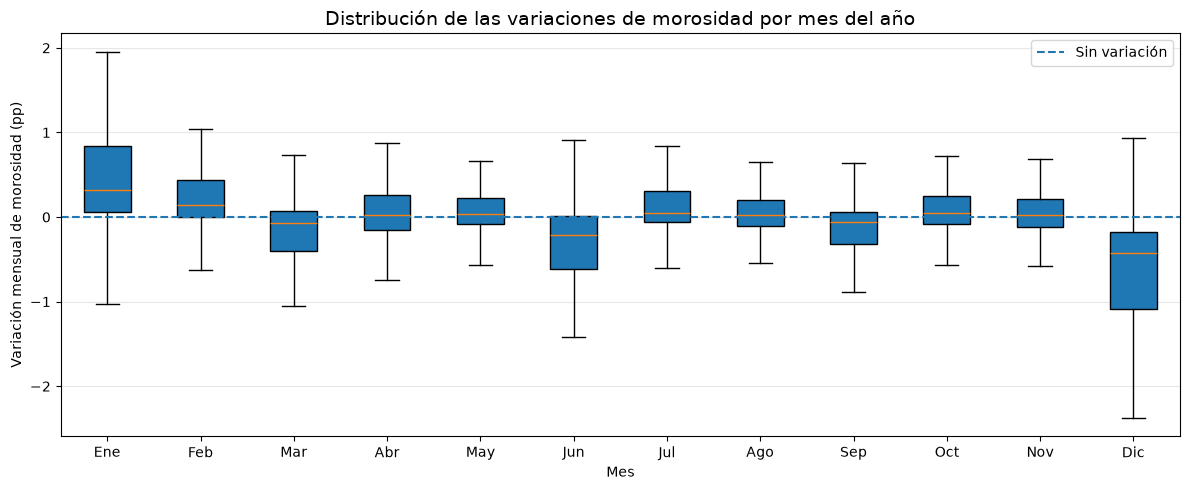

In [18]:
# Preparar datos para cada mes
datos_mensuales = [
    estacionalidad.loc[
        estacionalidad["mes"] == mes,
        "variacion_mensual_pp"
    ].to_numpy()
    for mes in range(1, 13)
]

# Etiquetas abreviadas
etiquetas = [
    "Ene", "Feb", "Mar", "Abr",
    "May", "Jun", "Jul", "Ago",
    "Sep", "Oct", "Nov", "Dic"
]

# Crear gráfico
fig, ax = plt.subplots(figsize=(12, 5))

ax.boxplot(
    datos_mensuales,
    showfliers=False,
    patch_artist=True
)

# Referencia: variación igual a cero
ax.axhline(
    0,
    linestyle="--",
    linewidth=1.5,
    label="Sin variación"
)

ax.set_xticks(
    range(1, 13),
    labels=etiquetas
)

ax.set_title(
    "Distribución de las variaciones de morosidad por mes del año",
    fontsize=14
)

ax.set_xlabel("Mes")
ax.set_ylabel("Variación mensual de morosidad (pp)")

ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

### Cambio mensual tipico

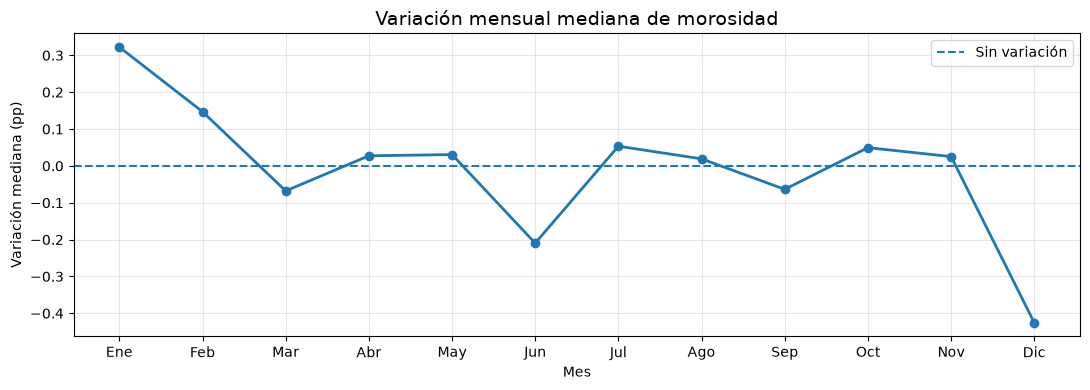

In [19]:
# Extraer medianas por mes
medianas = resumen_estacional["mediana"]

# Crear gráfico
fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(
    medianas.index,
    medianas.values,
    marker="o",
    linewidth=2,
    markersize=6
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1.5,
    label="Sin variación"
)

ax.set_xticks(
    range(1, 13),
    labels=etiquetas
)

ax.set_title(
    "Variación mensual mediana de morosidad",
    fontsize=14
)

ax.set_xlabel("Mes")
ax.set_ylabel("Variación mediana (pp)")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [20]:
# Evaluar estacionalidad en diferentes períodos históricos

revision_estacional = estacionalidad.copy()

revision_estacional["periodo"] = np.where(
    revision_estacional["fecha"].dt.year <= 2014,
    "2003-2014",
    "2015-2025"
)

# Seleccionar enero y diciembre
revision_estacional = revision_estacional.loc[
    revision_estacional["mes"].isin([1, 12])
]

# Comparar el comportamiento de ambos meses
resumen_periodos = (
    revision_estacional
    .groupby(["periodo", "mes"])["variacion_mensual_pp"]
    .agg(
        observaciones="count",
        media="mean",
        mediana="median",
        proporcion_incrementos=lambda x: (x > 0).mean()
    )
)

display(resumen_periodos.round(4))

observaciones     media   mediana  proporcion_incrementos
periodo   mes                                                           
2003-2014 1              211  0.638100  0.370100                0.872000
          12             232 -1.053000 -0.604500                0.077600
2015-2025 1              248  0.501400  0.255300                0.826600
          12             227 -0.600300 -0.369200                0.149800

El análisis de las variaciones mensuales evidencia un patrón estacional en la morosidad bancaria. Los incrementos se concentran especialmente en enero y febrero, mientras que las reducciones son más pronunciadas durante junio y diciembre. En particular, diciembre presenta una variación mediana de -0,426 puntos porcentuales y enero una variación mediana de +0,322 puntos porcentuales.
Este comportamiento sugiere la existencia de un componente estacional que podría aportar información predictiva. Sin embargo, será necesario comprobar su estabilidad entre instituciones y períodos históricos antes de establecer conclusiones definitivas. Durante el modelado se evaluará la utilidad de incorporar variables relacionadas con el mes del año.

## Analisis de Autocorrelacion y dependencia temporal

cuanta informacion contiene la morosidad historica para predecir sus valores futuros?

la autocorrelacion mide la relacion entre los valores de una varaible temporal y sus valores anteriores

Calcular las autocorrelaciones de cada banco y resumir los resultados

In [21]:
# Rezagos que queremos estudiar
rezagos = [1, 2, 3, 6, 12]


def calcular_autocorrelacion(serie, rezago):
    """
    Calcula la correlación entre una serie temporal
    y sus valores rezagados.

    Requiere al menos 24 pares válidos.
    """

    pares = pd.DataFrame({
        "actual": serie,
        "rezago": serie.shift(rezago)
    }).dropna()

    if len(pares) < 24:
        return np.nan

    return pares["actual"].corr(pares["rezago"])


# Almacenar resultados
resultados_acf = []

for banco, datos in desarrollo.groupby("banco"):

    # Construir serie mensual
    serie = (
        datos
        .set_index("fecha")["morosidad_pp"]
        .sort_index()
        .asfreq("MS")
    )

    # Calcular variaciones mensuales
    variaciones = serie.diff()

    for rezago in rezagos:

        resultados_acf.append({
            "banco": banco,
            "rezago": rezago,
            "variable": "morosidad",
            "autocorrelacion": calcular_autocorrelacion(
                serie, rezago
            )
        })

        resultados_acf.append({
            "banco": banco,
            "rezago": rezago,
            "variable": "variacion",
            "autocorrelacion": calcular_autocorrelacion(
                variaciones, rezago
            )
        })


# Convertir resultados a DataFrame
acf_bancos = pd.DataFrame(resultados_acf)

display(acf_bancos.head(10))

,banco,rezago,variable,autocorrelacion
0,BANCO ATLANTIDA S.A.,1,morosidad,0.979123
1,BANCO ATLANTIDA S.A.,1,variacion,0.026829
2,BANCO ATLANTIDA S.A.,2,morosidad,0.957773
3,BANCO ATLANTIDA S.A.,2,variacion,0.080529
4,BANCO ATLANTIDA S.A.,3,morosidad,0.932783
5,BANCO ATLANTIDA S.A.,3,variacion,0.091928
6,BANCO ATLANTIDA S.A.,6,morosidad,0.842344
7,BANCO ATLANTIDA S.A.,6,variacion,0.211982
8,BANCO ATLANTIDA S.A.,12,morosidad,0.603024
9,BANCO ATLANTIDA S.A.,12,variacion,0.078976


resumir las autocorrelaciones

In [22]:
# Resumir autocorrelaciones por variable y rezago
resumen_acf = (
    acf_bancos
    .groupby(["variable", "rezago"])["autocorrelacion"]
    .agg(
        bancos="count",
        media="mean",
        mediana="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

display(resumen_acf.round(4))

,variable,rezago,bancos,media,mediana,q1,q3
0,morosidad,1,23,0.907000,0.913300,0.881000,0.971500
1,morosidad,2,23,0.870200,0.882100,0.796900,0.951600
2,morosidad,3,23,0.859100,0.881000,0.830800,0.928800
3,morosidad,6,23,0.789900,0.806900,0.716700,0.873200
4,morosidad,12,23,0.645800,0.654900,0.497500,0.757300
5,variacion,1,23,-0.214000,-0.273600,-0.341300,-0.138200
6,variacion,2,23,-0.087200,-0.104800,-0.188200,0.004600
7,variacion,3,23,0.162700,0.122300,0.073200,0.211400
8,variacion,6,23,0.234200,0.214600,0.106800,0.319200
9,variacion,12,23,0.285200,0.242600,0.177000,0.349900


El análisis de autocorrelación evidencia una fuerte persistencia temporal en los niveles de morosidad bancaria. La autocorrelación mediana entre instituciones alcanza 0,913 para el primer rezago y disminuye gradualmente hasta 0,655 para el rezago de doce meses. Este comportamiento indica que los niveles actuales de morosidad contienen información relevante sobre su evolución posterior.
Las variaciones mensuales presentan una dinámica diferente. La autocorrelación mediana de primer orden es negativa (-0,274), lo que sugiere cierta tendencia a la reversión de los cambios mensuales. Asimismo, la autocorrelación positiva en el rezago de doce meses (0,243) es compatible con los patrones estacionales identificados anteriormente.
Estos resultados respaldan la utilización de la morosidad actual como predictor y justifican investigar rezagos, variaciones históricas y variables estacionales. No obstante, la selección definitiva de características deberá fundamentarse en su capacidad para mejorar las predicciones fuera de muestra frente al modelo de persistencia.

## Analisis multivariante de indicadores financieros

Investigar si los otros indicadores financieros contienen informacion sobre la morosidad futura

In [23]:
# Crear DataFrame de análisis
analisis_predictivo = (
    desarrollo
    .sort_values(["banco", "fecha"])
    .copy()
)

# Agrupar por institución
grupo = analisis_predictivo.groupby("banco")

# Obtener morosidad del mes siguiente
analisis_predictivo["morosidad_siguiente_pp"] = (
    grupo["morosidad_pp"].shift(-1)
)

# Obtener fecha del siguiente registro
analisis_predictivo["fecha_siguiente"] = (
    grupo["fecha"].shift(-1)
)

# Verificar continuidad mensual
mes_actual = (
    analisis_predictivo["fecha"].dt.to_period("M")
)

mes_siguiente = (
    analisis_predictivo["fecha_siguiente"].dt.to_period("M")
)

consecutivos = (
    mes_siguiente == mes_actual + 1
)

# Evitar relaciones entre meses no consecutivos
analisis_predictivo["morosidad_siguiente_pp"] = (
    analisis_predictivo["morosidad_siguiente_pp"]
    .where(consecutivos)
)

# Calcular el cambio de morosidad del siguiente mes
analisis_predictivo["cambio_siguiente_pp"] = (
    analisis_predictivo["morosidad_siguiente_pp"]
    - analisis_predictivo["morosidad_pp"]
)

# Comprobar resultados
display(
    analisis_predictivo[
        [
            "fecha",
            "banco",
            "morosidad_pp",
            "morosidad_siguiente_pp",
            "cambio_siguiente_pp"
        ]
    ].head(10)
)

print(
    "\nObservaciones con target futuro válido:",
    analisis_predictivo["morosidad_siguiente_pp"].notna().sum()
)

,fecha,banco,morosidad_pp,morosidad_siguiente_pp,cambio_siguiente_pp
0,2011-07-01,BANCO ATLANTIDA S.A.,2.600166,2.198235,-0.401930
1,2011-08-01,BANCO ATLANTIDA S.A.,2.198235,2.362087,0.163852
2,2011-09-01,BANCO ATLANTIDA S.A.,2.362087,2.466413,0.104326
3,2011-10-01,BANCO ATLANTIDA S.A.,2.466413,2.619950,0.153537
4,2011-11-01,BANCO ATLANTIDA S.A.,2.619950,2.230437,-0.389514
5,2011-12-01,BANCO ATLANTIDA S.A.,2.230437,2.682136,0.451699
6,2012-01-01,BANCO ATLANTIDA S.A.,2.682136,3.232366,0.550230
7,2012-02-01,BANCO ATLANTIDA S.A.,3.232366,2.989239,-0.243127
8,2012-03-01,BANCO ATLANTIDA S.A.,2.989239,3.347692,0.358453
9,2012-04-01,BANCO ATLANTIDA S.A.,3.347692,3.623611,0.275919



Observaciones con target futuro válido: 5668


### Calculo de las correlaciones predictivas

In [24]:
# Variables que queremos investigar
variables_financieras = [
    "morosidad_pp",
    "solvencia",
    "liquidez",
    "roa",
    "roe",
    "cartera_depositos",
    "cobertura",
    "cartera_bruta"
]

# Objetivos del análisis
objetivos = [
    "morosidad_siguiente_pp",
    "cambio_siguiente_pp"
]

resultados_corr = []

for objetivo in objetivos:

    for variable in variables_financieras:

        # Seleccionar pares válidos
        datos = analisis_predictivo[
            [variable, objetivo]
        ].dropna()

        # Calcular correlaciones
        pearson = datos[variable].corr(
            datos[objetivo],
            method="pearson"
        )

        spearman = datos[variable].corr(
            datos[objetivo],
            method="spearman"
        )

        resultados_corr.append({
            "objetivo": objetivo,
            "variable": variable,
            "observaciones": len(datos),
            "pearson": pearson,
            "spearman": spearman
        })

# Construir tabla
correlaciones = pd.DataFrame(resultados_corr)

display(
    correlaciones.round(4)
)

,objetivo,variable,observaciones,pearson,spearman
0,morosidad_siguiente_pp,morosidad_pp,5666,0.982900,0.968600
1,morosidad_siguiente_pp,solvencia,5665,0.239200,0.193200
2,morosidad_siguiente_pp,liquidez,5668,0.011100,-0.019700
3,morosidad_siguiente_pp,roa,5668,-0.581800,-0.221600
4,morosidad_siguiente_pp,roe,5668,-0.333800,-0.277700
5,morosidad_siguiente_pp,cartera_depositos,5668,0.009500,0.314500
6,morosidad_siguiente_pp,cobertura,5655,-0.097000,-0.765100
7,morosidad_siguiente_pp,cartera_bruta,5666,-0.146100,-0.329600
8,cambio_siguiente_pp,morosidad_pp,5666,-0.113700,-0.074100
9,cambio_siguiente_pp,solvencia,5665,-0.014600,-0.004500


Los resultados muestran algo que considero fundamental: la morosidad actual tiene una relación extraordinariamente fuerte con la morosidad del mes siguiente, mientras que los demás indicadores financieros presentan asociaciones mucho más débiles con sus variaciones futuras.

### Correlaciones por institucion

Las relaciones entre indicadores financieros y la morosidad futura son consistentes entre las distintas instituciones?

In [25]:
# Variables financieras
variables = [
    "morosidad_pp",
    "solvencia",
    "liquidez",
    "roa",
    "roe",
    "cartera_depositos",
    "cobertura",
    "cartera_bruta"
]

# Objetivos
objetivos = [
    "morosidad_siguiente_pp",
    "cambio_siguiente_pp"
]

resultados = []

# Calcular correlaciones por institución
for banco, datos_banco in analisis_predictivo.groupby("banco"):

    for objetivo in objetivos:

        for variable in variables:

            # Seleccionar pares válidos
            pares = (
                datos_banco[[variable, objetivo]]
                .replace([np.inf, -np.inf], np.nan)
                .dropna()
            )

            # Exigir suficientes observaciones
            if len(pares) < 36:
                continue

            # Evitar correlaciones con variables constantes
            if (
                pares[variable].nunique() < 2
                or pares[objetivo].nunique() < 2
            ):
                continue

            resultados.append({
                "banco": banco,
                "objetivo": objetivo,
                "variable": variable,
                "observaciones": len(pares),

                "pearson": pares[variable].corr(
                    pares[objetivo],
                    method="pearson"
                ),

                "spearman": pares[variable].corr(
                    pares[objetivo],
                    method="spearman"
                )
            })

# Construir DataFrame
correlaciones_bancos = pd.DataFrame(resultados)

display(correlaciones_bancos.head(10))

,banco,objetivo,variable,observaciones,pearson,spearman
0,BANCO ATLANTIDA S.A.,morosidad_siguiente_pp,morosidad_pp,170,0.979123,0.964951
1,BANCO ATLANTIDA S.A.,morosidad_siguiente_pp,solvencia,169,-0.514457,-0.633594
2,BANCO ATLANTIDA S.A.,morosidad_siguiente_pp,liquidez,170,-0.157115,0.056303
3,BANCO ATLANTIDA S.A.,morosidad_siguiente_pp,roa,170,-0.807029,-0.637012
4,BANCO ATLANTIDA S.A.,morosidad_siguiente_pp,roe,170,-0.779822,-0.603483
5,BANCO ATLANTIDA S.A.,morosidad_siguiente_pp,cartera_depositos,170,-0.242840,-0.206869
6,BANCO ATLANTIDA S.A.,morosidad_siguiente_pp,cobertura,170,-0.616071,-0.637848
7,BANCO ATLANTIDA S.A.,morosidad_siguiente_pp,cartera_bruta,170,-0.000648,0.159079
8,BANCO ATLANTIDA S.A.,cambio_siguiente_pp,morosidad_pp,170,-0.128451,0.006765
9,BANCO ATLANTIDA S.A.,cambio_siguiente_pp,solvencia,169,-0.035126,-0.043852


In [26]:
# Resumir correlaciones por variable y objetivo
resumen_correlaciones = (
    correlaciones_bancos
    .groupby(["objetivo", "variable"])
    .agg(
        bancos=("banco", "nunique"),

        pearson_mediana=("pearson", "median"),

        pearson_q1=(
            "pearson",
            lambda x: x.quantile(0.25)
        ),

        pearson_q3=(
            "pearson",
            lambda x: x.quantile(0.75)
        ),

        spearman_mediana=("spearman", "median"),

        proporcion_positivas=(
            "pearson",
            lambda x: (x > 0).mean()
        )
    )
    .reset_index()
)

# Resultados para morosidad futura
print("CORRELACIONES CON MOROSIDAD FUTURA")

display(
    resumen_correlaciones.loc[
        resumen_correlaciones["objetivo"]
        == "morosidad_siguiente_pp"
    ].round(4)
)

# Resultados para cambio futuro
print("\nCORRELACIONES CON CAMBIO FUTURO")

display(
    resumen_correlaciones.loc[
        resumen_correlaciones["objetivo"]
        == "cambio_siguiente_pp"
    ].round(4)
)

CORRELACIONES CON MOROSIDAD FUTURA


,objetivo,variable,bancos,pearson_mediana,pearson_q1,pearson_q3,spearman_mediana,proporcion_positivas
8,morosidad_siguiente_pp,cartera_bruta,23,-0.299100,-0.462400,0.180000,-0.202500,0.347800
9,morosidad_siguiente_pp,cartera_depositos,23,-0.127100,-0.367400,0.086600,-0.139700,0.304300
10,morosidad_siguiente_pp,cobertura,23,-0.597200,-0.673700,-0.416600,-0.717500,0.043500
11,morosidad_siguiente_pp,liquidez,23,-0.093200,-0.195000,0.226200,-0.069800,0.391300
12,morosidad_siguiente_pp,morosidad_pp,23,0.913300,0.881000,0.971500,0.909200,1.000000
13,morosidad_siguiente_pp,roa,23,-0.143200,-0.382500,0.300300,-0.172000,0.434800
14,morosidad_siguiente_pp,roe,23,-0.089800,-0.278100,0.288500,-0.109000,0.391300
15,morosidad_siguiente_pp,solvencia,23,-0.141900,-0.280500,0.162200,-0.102000,0.304300



CORRELACIONES CON CAMBIO FUTURO


,objetivo,variable,bancos,pearson_mediana,pearson_q1,pearson_q3,spearman_mediana,proporcion_positivas
0,cambio_siguiente_pp,cartera_bruta,23,0.032400,0.009100,0.085100,0.026400,0.869600
1,cambio_siguiente_pp,cartera_depositos,23,0.040500,0.013400,0.068200,0.022700,0.869600
2,cambio_siguiente_pp,cobertura,23,0.157500,0.085200,0.220400,0.116800,0.913000
3,cambio_siguiente_pp,liquidez,23,-0.002000,-0.041200,0.028300,-0.014800,0.391300
4,cambio_siguiente_pp,morosidad_pp,23,-0.225300,-0.287200,-0.174500,-0.158000,0.000000
5,cambio_siguiente_pp,roa,23,0.003500,-0.039900,0.044100,0.021900,0.565200
6,cambio_siguiente_pp,roe,23,-0.009000,-0.033600,0.040400,0.026300,0.391300
7,cambio_siguiente_pp,solvencia,23,0.001200,-0.050000,0.021800,-0.034400,0.521700


## Conclusiones de todo el EDA

3.8.1. Calidad y estructura del dataset

El proceso de extracción permitió construir un panel histórico de información financiera correspondiente a 23 instituciones bancarias ecuatorianas, con 5.972 observaciones mensuales entre enero de 2003 y septiembre de 2026.
La estructura del dataset es desbalanceada, debido a que las instituciones presentan diferentes períodos de cobertura histórica. Sin embargo, esto no impide su utilización en modelos de aprendizaje supervisado, siempre que se respete la continuidad temporal de cada institución.
La validación financiera confirmó que los indicadores de morosidad coinciden con los calculados mediante los saldos de cartera bruta e improductiva, con diferencias numéricas inferiores a la tolerancia establecida.
Se identificaron seis observaciones de Delbank con cartera bruta igual a cero, cuya morosidad no es matemáticamente verificable. Estos registros se conservaron, representando las variables afectadas mediante valores faltantes.
También se identificaron valores faltantes de solvencia y cobertura, así como ceros en determinados indicadores de liquidez y rentabilidad que requieren una interpretación cuidadosa.
En general, el dataset presenta una calidad adecuada para continuar hacia las siguientes fases del proyecto.

3.8.2. Cobertura temporal

El análisis de cobertura histórica mostró que la cantidad de instituciones representadas aumentó progresivamente desde 18 bancos en 2003 hasta alcanzar las 23 instituciones aproximadamente entre 2017 y 2018.
La cobertura media durante los 285 meses analizados fue de aproximadamente 20,95 instituciones.
La disponibilidad de morosidad es elevada, con 5.966 observaciones verificables de un total de 5.972 registros, equivalente aproximadamente al 99,90 % del panel.
Estos resultados respaldan la decisión de conservar todos los períodos históricos disponibles y trabajar inicialmente con un panel desbalanceado.
No obstante, las diferencias de cobertura implican que algunas instituciones tendrán una mayor representación en el entrenamiento. Por esta razón, será necesario evaluar los modelos tanto globalmente como por institución.

3.8.3. Distribución de la morosidad

El análisis univariante evidenció una distribución asimétrica hacia la derecha.

La diferencia entre la media y la mediana indica que las observaciones elevadas influyen considerablemente en el promedio.
Asimismo, el percentil 99 y el valor máximo muestran que existen episodios extraordinarios de morosidad.
Esta distribución justifica utilizar métricas robustas e investigar los errores predictivos durante períodos de deterioro crediticio elevado.
Los valores extremos financieramente verificables no serán eliminados automáticamente del conjunto de datos.

3.8.4. Heterogeneidad institucional

El análisis por institución reveló diferencias importantes tanto en los niveles centrales de morosidad como en su dispersión.
Banco Capital destacó por presentar la mayor variabilidad, con una desviación estándar aproximada de 19,14 puntos porcentuales y un máximo de 87,04 %.
Por su parte, Banco Litoral registró una de las medianas de morosidad más elevadas, mientras que instituciones como Banco Internacional y Banco Bolivariano presentaron niveles históricamente menores y distribuciones relativamente concentradas.
Estas diferencias muestran que los bancos no necesariamente siguen una misma dinámica crediticia.
Por tanto, será importante investigar si los modelos pueden representar adecuadamente las particularidades institucionales y comprobar si existen diferencias importantes en sus errores predictivos.

3.8.5. Evolución histórica y episodios extremos

El análisis temporal individualizado permitió identificar episodios de morosidad elevada y cambios significativos en su comportamiento histórico.
Banco Capital experimentó un incremento considerable de morosidad entre 2017 y 2019. Este comportamiento coincidió con una fuerte contracción de su cartera bruta, mientras que la cartera improductiva disminuyó proporcionalmente menos.
Banco Atlántida presentó distintos períodos de incremento y reducción de morosidad, mientras que Banco Pacífico mostró una disminución considerable desde los niveles elevados registrados al inicio de su serie histórica.
Estos resultados evidencian que las relaciones financieras pueden cambiar a lo largo del tiempo.
Por ello, durante el modelado será conveniente comparar estrategias de entrenamiento que utilicen historiales completos frente a ventanas temporales más recientes.

3.8.6. Morosidad promedio y morosidad ponderada

La comparación entre la morosidad promedio institucional y la morosidad ponderada por cartera reveló diferencias importantes.
Durante mayo de 2019, la morosidad promedio institucional alcanzó aproximadamente el 8,02 %, mientras que la morosidad ponderada fue del 3,05 %.
La diferencia de 4,97 puntos porcentuales coincide con el episodio de elevada morosidad registrado por Banco Capital.
Este resultado demuestra que las instituciones con carteras relativamente pequeñas pueden influir considerablemente en el promedio institucional sin producir un efecto equivalente sobre el indicador ponderado.
Por tanto, ambos indicadores deben interpretarse de manera diferente.
La morosidad ponderada representa la proporción de cartera improductiva respecto al volumen total de cartera incluido en el panel, mientras que el promedio institucional asigna el mismo peso a cada banco.

3.8.7. Variaciones mensuales

El análisis de las variaciones mensuales evidenció una relativa estabilidad de corto plazo.
La variación mediana fue aproximadamente de 0,004 puntos porcentuales, mientras que la variación absoluta mediana alcanzó 0,222 puntos porcentuales. La variacion absoluta media fue: 0.5429 pp.
Este valor constituye una referencia histórica preliminar del error absoluto medio de un modelo de persistencia.
Sin embargo, también se identificaron 42 episodios con variaciones absolutas superiores a cinco puntos porcentuales.
Estos resultados indican que, aunque la mayoría de las observaciones presenta cambios moderados, existen períodos con fluctuaciones extraordinarias.
Por tanto, el modelo deberá ser evaluado tanto en situaciones habituales como durante episodios de cambios importantes.

3.8.8. Estacionalidad

El análisis estacional evidenció patrones recurrentes en las variaciones mensuales de morosidad.
Los meses de enero y febrero presentaron incrementos predominantemente positivos, mientras que junio y diciembre registraron reducciones más pronunciadas.
En particular: El cambio en enero = +0.3222 pp y el cambio en diciembre = -0.4256.

Asimismo, el 84,75 % de las observaciones de enero presentó incrementos, frente al 11,33 % registrado durante diciembre.
La comparación entre los períodos 2003–2014 y 2015–2025 mostró que ambos patrones conservaron su dirección, aunque con diferencias en su magnitud.
Esto constituye evidencia descriptiva de un componente estacional relativamente persistente.
Por tanto, se justifica evaluar variables asociadas al mes del año durante el entrenamiento.
No obstante, todavía debe comprobarse si dichas características mejoran las predicciones fuera de muestra.

3.8.9. Autocorrelación y dependencia temporal

Los resultados de autocorrelación mostraron una fuerte persistencia en los niveles de morosidad.
La autocorrelación mediana de primer orden entre instituciones fue: 0.9133, mientras que para el rezago de 12 meses se obtuvo: 0.6549.
Estos resultados indican que los valores anteriores de morosidad contienen información relevante sobre su comportamiento posterior.
En contraste, las variaciones mensuales presentaron una autocorrelación mediana negativa en el primer rezago: -0.2736., y una autocorrelacion positiva en el rezago de doce meses: 0.2426.
Estos resultados son compatibles con cierta reversión de los cambios mensuales y con los patrones estacionales identificados previamente.
Sin embargo, no permiten establecer por sí solos un mecanismo causal ni garantizan que dichos patrones sean estables en períodos futuros.
En conjunto, los resultados justifican incorporar la morosidad histórica, variaciones mensuales y características estacionales como predictores candidatos.

3.8.10. Relaciones entre indicadores financieros y morosidad futura

El análisis multivariante mostró que la morosidad actual presenta una asociación positiva muy elevada con la morosidad del mes siguiente.
La correlación de Pearson calculada conjuntamente sobre las observaciones del panel alcanzó 0,9829.
Sin embargo, las correlaciones institucionales presentaron una mediana de 0,9133, reflejando diferencias en la dependencia temporal de los bancos.
La cobertura mostró una asociación negativa relativamente consistente con la morosidad futura, con una correlación institucional mediana de -0,5972.
Por otro lado, ROA, ROE, liquidez y solvencia presentaron relaciones heterogéneas entre instituciones.
Las asociaciones con las variaciones futuras de morosidad fueron considerablemente menores.
En particular, la morosidad actual presentó una correlación institucional mediana de -0,2253 con el cambio del mes siguiente, mientras que la cobertura registró una mediana de +0,1575.
Estos resultados sugieren que la morosidad actual concentra una parte importante de la información relacionada con su nivel futuro.
No obstante, las correlaciones individuales no permiten determinar si los indicadores financieros aportan información predictiva adicional.
Esta cuestión deberá evaluarse mediante modelos supervisados y validación temporal.

3.8.11. Implicaciones generales para el modelado

Los resultados del EDA permiten establecer las siguientes decisiones metodológicas:
1. Se conservará inicialmente el panel histórico desbalanceado, evitando descartar información únicamente por diferencias de cobertura entre instituciones.
2. La morosidad actual será el predictor de referencia, debido a su fuerte persistencia temporal.
3. Se incorporarán como características candidatas los rezagos de morosidad, sus variaciones mensuales y las variables estacionales.
4. Se evaluará la contribución de indicadores financieros como cobertura, liquidez, solvencia, ROA, ROE y relación cartera/depósitos.
5. Los valores extremos financieramente consistentes se conservarán, evaluando posteriormente su influencia sobre el entrenamiento.
6. Se utilizará validación temporal para evitar que la información futura intervenga en el ajuste de los modelos.
7. Se compararán los resultados con el baseline de persistencia y se evaluará el desempeño tanto globalmente como por institución.
En conclusión, el EDA muestra que la morosidad bancaria presenta una elevada dependencia temporal, heterogeneidad institucional y patrones estacionales en sus variaciones mensuales.
Estos hallazgos permiten formular una pregunta central para la siguiente fase:

¿Pueden las variables temporales y los indicadores financieros mejorar la predicción de morosidad del mes siguiente respecto de un modelo que simplemente conserva el valor actual?

